# Audience Network

### Librerie utilizzate

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
import pandas as pd
import seaborn as sns
import numpy as np
import json
import random
from scipy import stats
# from multiprocessing import Pool, cpu_count # proiezione commentatori
import itertools
from tqdm import tqdm

## Network Creation

### Costruzione della rete bipartita dell'audience dei creators in tendenza

La rete ha 2.5M circa di nodi e 3M di edges. Per tale motivo non verrà visualizzata nemmeno su Gephi (carica la rete ma tutte le modifiche di Layout, se riescono ad essere eseguite, impiegano troppo tempo), tuttavia ne verrà creato il file .ghepix

In [12]:
# Dal file .json ottenuto nella fase di Data Gathering con struttura { gruppo : [ attori ] }
with open('Data/audience.json', 'r') as f:
    audience = json.load(f)

B = nx.Graph()

for creator, commenters in audience.items():
    
    for commenter in commenters:
        
        if commenter in audience.keys(): continue
        
        if not B.has_node(creator):

            B.add_node(creator, bipartite=0)  # Aggiungo il nodo "creator" al set 0

        if not B.has_node(commenter):

            B.add_node(commenter, bipartite=1)  # Aggiungo il nodo "commentator" al set 1

        B.add_edge(creator, commenter)  # Aggiungo un arco tra il "creator" e il "commenter"

network_title = "Audience dei creators in tendenza"

In [3]:
# Salvo il grafo per poterlo vedere su Ghepi

nx.write_gexf(B, "Networks_Gephi/audience.gexf")

### Disegno della rete
La rete è troppo grande per essere disegnata dal mio hardware.

## Network Analysis

### Metriche Base:

In [3]:
# Metriche base

print("Number of nodes:", B.number_of_nodes())

print("Number of edges:", B.number_of_edges())

Number of nodes: 2491012
Number of edges: 3091570


### Distribuzione del grado

Nodi Creators = 2057
Nodi Commenter = 2488955
Distribuzione del grado dei creators:
count    2057.000000
mean     1502.950899
std       971.831140
min         1.000000
25%       369.000000
50%      1821.000000
75%      2346.000000
max      2866.000000
dtype: float64
Mediana del grado dei creators: 1821.0
Moda del grado dei creators: 1
Frequenza della moda dei creators: 37


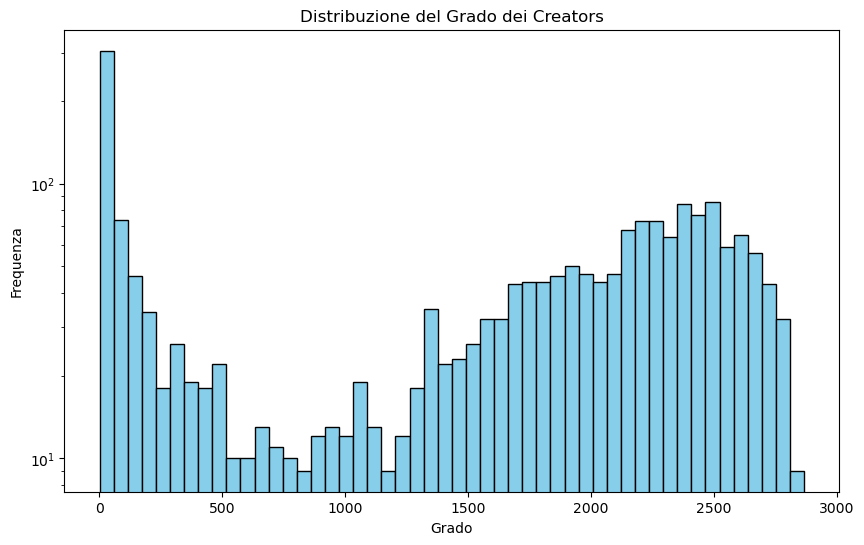

Distribuzione del grado dei commentatori:
count    2.488955e+06
mean     1.242116e+00
std      9.629348e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      7.010000e+02
dtype: float64
Mediana del grado dei commentatori: 1.0
Moda del grado dei commentatori: 1
Frequenza della moda dei commentatori: 2121228


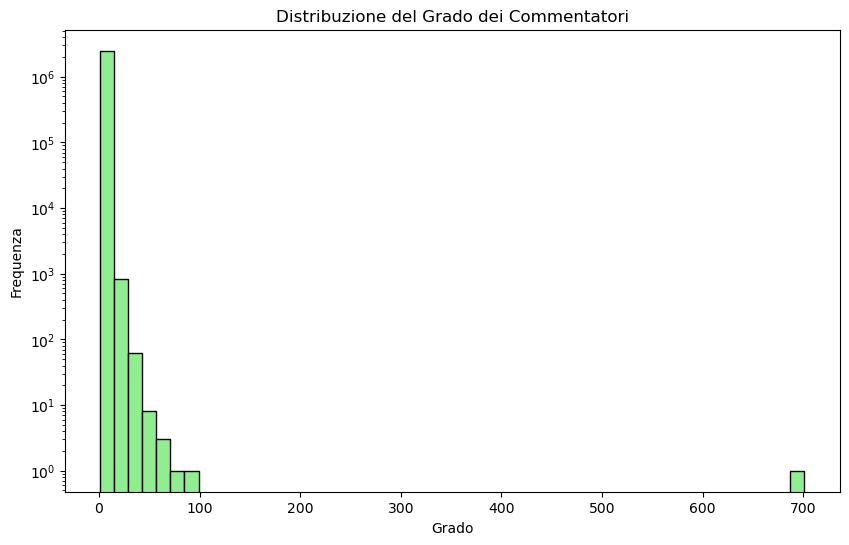

Densità della rete bipartita: 0.0006038481609221588


In [13]:
# Distribuzione del Grado
creator_nodes = {n for n, d in B.nodes(data=True) if d['bipartite'] == 0} # Conto i creators, che sono meno
commenter_nodes = set(B) - creator_nodes # Dal grafo totale escludo i creators e trovo i commentatori

creator_degree = B.degree(creator_nodes)
commenter_degree = B.degree(commenter_nodes)

print(f"Nodi Creators = {len(creator_nodes)}")
print(f"Nodi Commenter = {len(commenter_nodes)}")

creator_degree_series = pd.Series(dict(creator_degree))
print("Distribuzione del grado dei creators:")
print(creator_degree_series.describe())
print(f"Mediana del grado dei creators: {creator_degree_series.median()}")
print(f"Moda del grado dei creators: {stats.mode(creator_degree_series)[0]}")
print(f"Frequenza della moda dei creators: {creator_degree_series.value_counts().iloc[0]}")

# Visualizzazione della distribuzione dei gradi dei creators
plt.figure(figsize=(10, 6))
plt.hist(creator_degree_series, bins=50, color='skyblue', edgecolor='black', orientation='vertical')
plt.title('Distribuzione del Grado dei Creators')
plt.ylabel('Frequenza')
plt.xlabel('Grado')
plt.yscale('log')  # Scala logaritmica per migliorare la visualizzazione
plt.show()

commenter_degree_series = pd.Series(dict(commenter_degree))
print("Distribuzione del grado dei commentatori:")
print(commenter_degree_series.describe())
print(f"Mediana del grado dei commentatori: {commenter_degree_series.median()}")
print(f"Moda del grado dei commentatori: {stats.mode(commenter_degree_series)[0]}")
print(f"Frequenza della moda dei commentatori: {commenter_degree_series.value_counts().iloc[0]}")

# Visualizzazione della distribuzione dei gradi dei commentatori
plt.figure(figsize=(10, 6))
plt.hist(commenter_degree_series, bins=50, color='lightgreen', edgecolor='black', orientation='vertical')
plt.title('Distribuzione del Grado dei Commentatori')
plt.ylabel('Frequenza')
plt.xlabel('Grado')
plt.yscale('log')  # Scala logaritmica per migliorare la visualizzazione
plt.show()


# Densità della Rete
density = bipartite.density(B, creator_nodes)
print("Densità della rete bipartita:", density)

### Connettività

In [5]:
# Componenti Connesse

connected_components = list(nx.connected_components(B))

largest_cc = max(connected_components, key=len)

# Grandezza media delle componenti connesse escluse da quella più grande
sizes_of_other_components = [len(component) for component in connected_components if component != largest_cc]
average_size_other_components = sum(sizes_of_other_components) / len(sizes_of_other_components) if sizes_of_other_components else 0

print("Numero di componenti connesse:", len(connected_components))
print("Dimensione della componente connessa più grande:", len(largest_cc))
print("Grandezza media delle componenti connesse escluse da quella più grande:", average_size_other_components)

Numero di componenti connesse: 171
Dimensione della componente connessa più grande: 2488297
Grandezza media delle componenti connesse escluse da quella più grande: 15.970588235294118


### Diametro approssimato della componente connessa più grande

In [37]:
subgraph = B.subgraph(largest_cc).copy()
approx_avg_path_length = nx.approximation.diameter(subgraph)
print("Diametro approssimato della componente connessa più grande:", approx_avg_path_length)

Diametro approssimato della componente connessa più grande: 12


### Campionamento della Rete (300 000 nodi) - Calcolo Clustering Medio Bipartito e AvgShortestPath
Una stima approssimativa del AvgShortestPath usando un campione di tutta la rete. Per un'approssimazione più precisa richiede un numero elavato di nodi campioni, che aumentano il tempo di esecuzione.

In [9]:
def combined_sampled_metrics(B, sample_size=300000, clustering_mode='dot'):
    nodes = list(B.nodes())
    sampled_nodes = random.sample(nodes, sample_size)
    total_path_length = 0
    total_pairs = 0
    total_clustering = 0
    total_nodes_clustering = 0
    
    subgraph = B.subgraph(sampled_nodes).copy()
    print(f"Numero di nodi nel sottografo campionato: {len(subgraph.nodes())}")
    
    # Calcolo della lunghezza media del cammino per il campione
    path_lengths = dict(nx.all_pairs_shortest_path_length(subgraph))
    for source, lengths in tqdm(path_lengths.items(), desc="Average shortest path (campionary)", unit="node"):
        total_path_length += sum(lengths.values())
        total_pairs += len(lengths) - 1  # exclude self-loops
    
    # Calcolo del clustering bipartito per il campione
    print("Inizio calcolo del clustering bipartito")
    clustering = nx.bipartite.clustering(subgraph, mode=clustering_mode)
    total_clustering += sum(clustering.values())
    total_nodes_clustering += len(clustering)
    
    average_path_length = total_path_length / total_pairs if total_pairs > 0 else 0
    average_clustering = total_clustering / total_nodes_clustering if total_nodes_clustering > 0 else 0
    
    return average_path_length, average_clustering

try:
    average_path_length_sampled, average_clustering_sampled = combined_sampled_metrics(B)
    print("Lunghezza media del cammino (campionamento):", average_path_length_sampled)
    print("Coefficiente di clustering bipartito (campionamento):", average_clustering_sampled)
except Exception as e:
    print(f"Errore nel calcolo delle metriche: {e}")


Numero di nodi nel sottografo campionato: 300000


Average shortest path (campionary): 100%|██████████| 300000/300000 [02:22<00:00, 2100.16node/s]


Inizio calcolo del clustering bipartito
Lunghezza media del cammino (campionamento): 7.736557463768754
Coefficiente di clustering bipartito (campionamento): 0.12778109313506056


### Sottografi Batch (20 000 nodi) - Calcolo del Clustering Medio Bipartito e AvgShortest Path
Non tiene in considerazione i nodi al di fuori del batch nel calcolo. Computazionalmente fattibile ma sottostima il risultato a causa dell'esclusione dei nodi al di fuori del batch.

In [10]:
def combined_metrics(B, batch_size=20000, clustering_mode='dot'):
    nodes = list(B.nodes())
    total_clustering = 0
    total_nodes_clustering = 0
    total_path_length = 0
    total_pairs = 0
    
    for i in tqdm(range(0, len(nodes), batch_size), desc="Calculating Metrics", unit="batch"):
        batch = nodes[i:i + batch_size]
        subgraph = B.subgraph(batch).copy()
        
        if len(subgraph) < 2:
            continue
        
        # Calcolo del clustering bipartito per il batch
        clustering = nx.bipartite.clustering(subgraph, mode=clustering_mode)
        total_clustering += sum(clustering.values())
        total_nodes_clustering += len(clustering)
        
        # Calcolo della lunghezza media del cammino per il batch
        path_lengths = dict(nx.all_pairs_shortest_path_length(subgraph))
        for source, lengths in path_lengths.items():
            total_path_length += sum(lengths.values())
            total_pairs += len(lengths) - 1  # exclude self-loops

    average_clustering = total_clustering / total_nodes_clustering if total_nodes_clustering > 0 else 0
    average_path_length = total_path_length / total_pairs if total_pairs > 0 else 0
    
    return average_clustering, average_path_length

try:
    average_clustering_bipartito, average_path_length_bipartito = combined_metrics(B)
    print("Coefficiente di clustering bipartito (calcolo sottografi batch):", average_clustering_bipartito)
    print("Lunghezza media del cammino (calcolo sottografi batch):", average_path_length_bipartito)
except Exception as e:
    print(f"Errore nel calcolo delle metriche: {e}")


Calculating Metrics: 100%|██████████| 125/125 [5:06:41<00:00, 147.21s/batch]  


Coefficiente di clustering bipartito (calcolo sottografi batch): 0.9529829982261224
Lunghezza media del cammino (calcolo sottografi batch): 4.399806027322316


## Proiezioni Unipartite

### Proiezione sui Creators (gruppi)
Due Creators condividono un link se hanno in comune almeno 400 commenters.

In [14]:
# Proiezione Unipartita - Creators (gruppi)
G_creator = bipartite.projected_graph(B, creator_nodes)

# Soglia minima di commenters comuni per creare un arco
min_shared_commenters = 400

# Rimuovo gli archi che non soddisfano la soglia minima dei commenters condivisi
edges_to_remove = []

for u, v in tqdm(G_creator.edges(), desc="Proiezione Creators", unit="link"):
    
    shared_commenters = len(set(B[u]) & set(B[v]))
    
    if shared_commenters < min_shared_commenters:
        edges_to_remove.append((u, v))

# Rimuovo gli archi dalla rete
G_creator.remove_edges_from(edges_to_remove)

print("Proiezione unipartita dei creators - Numero di nodi:", G_creator.number_of_nodes())
print("Proiezione unipartita dei creators - Numero di archi:", G_creator.number_of_edges())
print(f"Nodi Isolati: {len(list(nx.isolates(G_creator)))}")

Proiezione Creators: 100%|██████████| 435055/435055 [01:09<00:00, 6282.45link/s]


Proiezione unipartita dei creators - Numero di nodi: 2057
Proiezione unipartita dei creators - Numero di archi: 83
Nodi Isolati: 1894


### Disegno della Rete

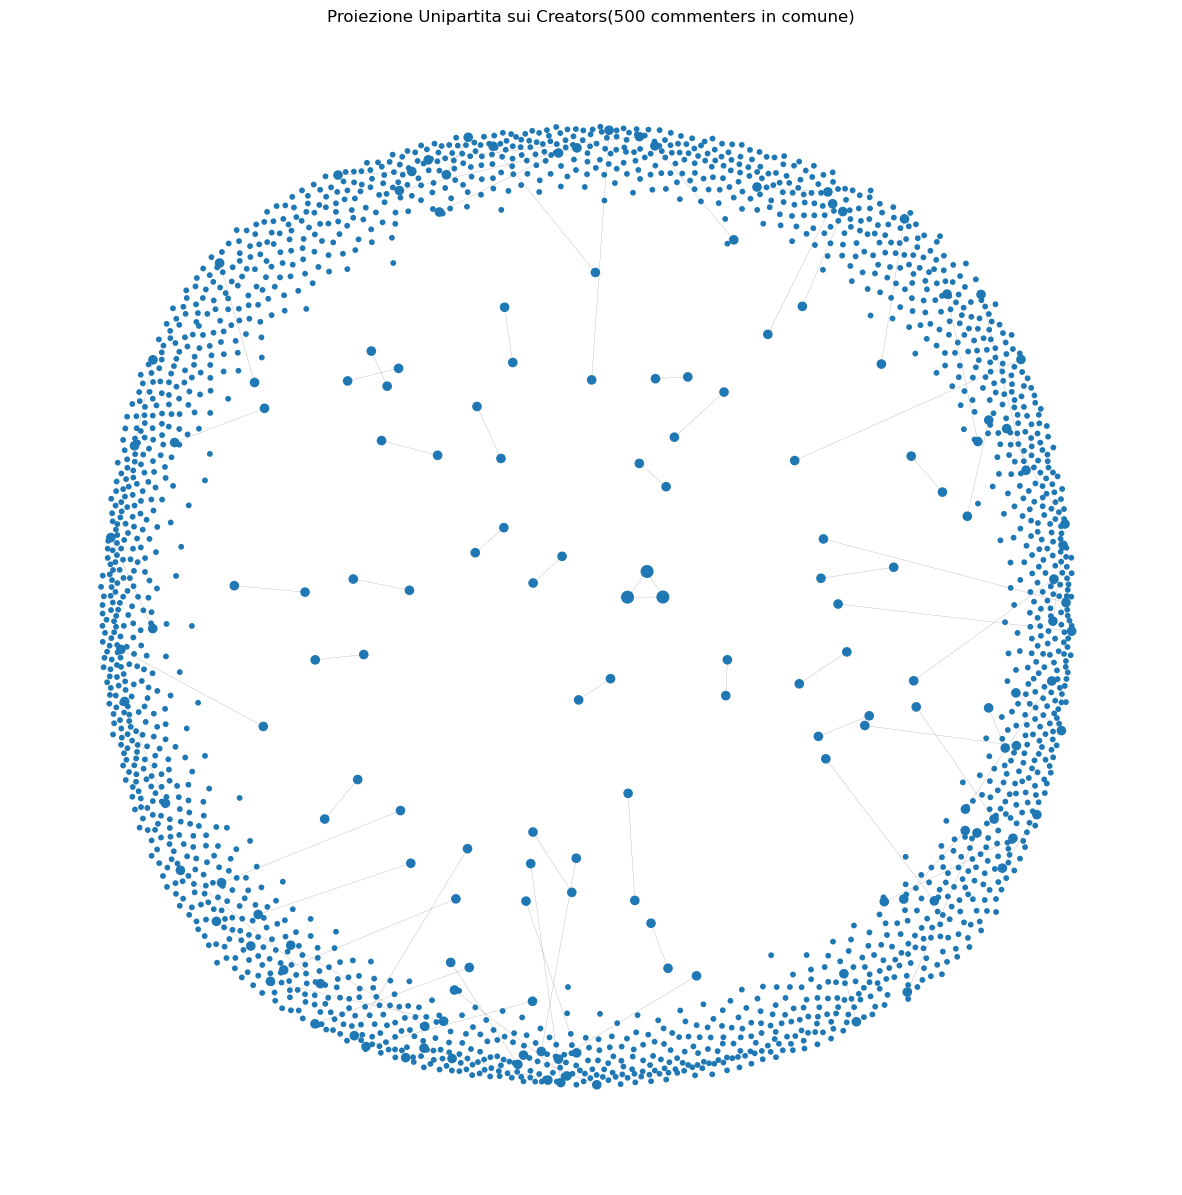

In [15]:
# Disegno della rete
pos = nx.spring_layout(G_creator, seed=42, k=0.2)  # Seed per avere un layout riproducibile

# Grado per ciascun nodo
degree_dict = dict(G_creator.degree(G_creator.nodes()))

# Scala della dimensione in base al grado
node_size = [v * 35 if v > 0 else 10 for v in degree_dict.values()]

plt.figure(figsize=(15, 15))
nodes = nx.draw_networkx_nodes(G_creator, pos, node_size=node_size, node_color='#1f78b4')
edges = nx.draw_networkx_edges(G_creator, pos, alpha=0.5, edge_color='#616060',  width=0.25)

plt.title("Proiezione Unipartita sui Creators(500 commenters in comune)")
plt.axis('off')

plt.show()

### Assortatività

In [16]:
# Assortatività
assortativity = nx.degree_assortativity_coefficient(G_creator)
print("Assortatività:", assortativity)

Assortatività: 1.000000000000003


Questo valore ovviamente non è valido per l'analisi, in quanto calcola solo sui nodi rimanente ed erroneamente risulta in un'assortatività apparentemente perfetta. Non considerando i nodi isolati.

### Proiezione sui Commenter (attori)
Proiettare sui commentatori (2.488.955 nodi) risulta troppo oneroso in termini di tempo di esecuzione per il mio hardware.

## Audience Overlapping

### Jaccard Similarity
Valuta la similarità tra due set misurando la proporzione tra l'intersezione e l'unione dei set.
Valuta quindi la similarità di due Creators in proporzione ai commentatori che hanno in comune nello loro audience.

In [17]:
# Funzione per calcolare il coefficiente di Jaccard tra due set
def jaccard_coefficient(set1, set2):
    intersection = len(set1 & set2)
    union = len(set1 | set2)
    if union == 0:
        return 0
    return intersection / union

### Adamic Adar
Misura la similarità tra due nodi tenendo conto della rarità dei loro vicini comuni.
Valuta quanto due creators sono simili considerando i commentatori che hanno in comune. I vicini comuni con un numero minore di collegamenti (creators che hanno un pubblico ristretto) contribuiscono di più alla similarità.

In [18]:
# Funzione per calcolare l'Adamic-Adar Index
def adamic_adar_index(graph, node1, node2):
    # Calcola Adamic-Adar Index per la coppia di nodi
    preds = list(nx.adamic_adar_index(graph, [(node1, node2)]))
    if preds:
        return preds[0][2]
    return 0

### Preferential Attachment
Misura la probabilità che due nodi formino un collegamento basato sui loro gradi.

In [19]:
# Funzione per calcolare il Preferential Attachment
def preferential_attachment(graph, node1, node2):
    # Calcola Preferential Attachment per la coppia di nodi
    preds = list(nx.preferential_attachment(graph, [(node1, node2)]))
    if preds:
        return preds[0][2]
    return 0

### Resource allocation
Valuta la similarità tra due nodi basandosi sulla distribuzione delle risorse attraverso i loro vicini comuni.
Valuta quanto due creators sono simili considerando i commentatori comuni e ponderando maggiormente quelli con meno collegamenti.

In [20]:
# Funzione per calcolare il Resource Allocation Index
def resource_allocation_index(graph, node1, node2):
    if node1 in graph and node2 in graph:
        preds = list(nx.resource_allocation_index(graph, [(node1, node2)]))
        if preds:
            return preds[0][2]
    return 0

### Calcolo dei coefficenti per ogni coppia di nodi

In [21]:
# Dizionario delle audience
audience_data = {creator: set(commenters) for creator, commenters in audience.items()}

print(f"Dizionario Creators : Audience totali {len(audience_data)}")

Dizionario Creators : Audience totali 2059


In [22]:
# Calcolo delle metriche per ogni coppia di creators
similarity = {}

combinations = list(itertools.combinations(audience_data.keys(), 2))

positive_jaccard_count = 0
positive_adamic_count = 0
positive_preferential_count = 0
positive_resource_count = 0

for creator1, creator2 in tqdm(combinations, desc="Calcolo dei coefficienti di similarità"):
    
    if creator1 in G_creator.nodes() and creator2 in G_creator.nodes():
    
        jaccard = jaccard_coefficient(audience_data[creator1], audience_data[creator2])

        adamic = adamic_adar_index(G_creator, creator1, creator2)

        preferential = preferential_attachment(G_creator, creator1, creator2)
        
        resource = resource_allocation_index(G_creator, creator1, creator2)
    
        if(jaccard > 0) :
            positive_jaccard_count += 1
        if(jaccard > 0) :
            positive_adamic_count += 1
        if(jaccard > 0) :
            positive_preferential_count += 1
        if(jaccard > 0) :
            positive_resource_count += 1
    
    else: # se uno o entrambi i creator non hanno audience non compaiono nel grafo unipartito e non avranno similarità
        jaccard = 0
        adamic = 0
        preferential = 0
        resource = 0
    
    similarity[(creator1, creator2)] = [jaccard, adamic, preferential, resource]

# Sanity check
i = 0
for pair, sim in similarity.items():
        i = i + 1
        print(f"{i} - {pair[0]} e {pair[1]}: Jaccard {sim[0]:.4f}, Adamic {sim[1]:.4f}, Preferential {sim[2]:.4f}, Resource {sim[3]:.4f}")
        if i == 20: break
print(f"Numero metriche positive: Jaccard = {positive_jaccard_count} ; Adamic Adar = {positive_adamic_count} ; Preferential Attachment = {positive_preferential_count} ; Resource Allocation = {positive_resource_count}")

Calcolo dei coefficienti di similarità: 100%|██████████| 2118711/2118711 [05:30<00:00, 6414.11it/s] 

1 - ysterik e BBC: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
2 - ysterik e OnsOranje: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
3 - ysterik e rolandpollard: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
4 - ysterik e ambraofficial: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
5 - ysterik e nyknicks: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
6 - ysterik e CallofDuty: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
7 - ysterik e pledis17: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
8 - ysterik e Pokemonufficiale: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
9 - ysterik e MemGrizz: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
10 - ysterik e grax: Jaccard 0.0000, Adamic 0.0000, Preferential 0.0000, Resource 0.0000
11 - ysterik e ctvnews: Jaccard 0.0000, Adamic 0.0000, Preferential

In [23]:
print(f"Coppie totali = {len(similarity)}")

Coppie totali = 2118711


In [24]:
# Salvo il file delle coppie con rispettivi indici di similarità

# Convertire la coppia in una stringa
def tuple_to_str(t):
    return f"{t[0]} ; {t[1]}"

# Creo un nuovo dizionario con ogni chiave convertita in stringa
similarity_str_keys = {tuple_to_str(k_pair): similarities for k_pair, similarities in similarity.items()}

# Salvo il dizionario come JSON per la creazione del Dataset per il ML e l'analisi qualitativa
with open('Data/similarity.json', 'w') as f:
    json.dump(similarity_str_keys, f)

## Audience Overlapping e Communities

In [2]:
# File delle partizioni
with open('Data/partition.json', 'r') as f:
    partition = json.load(f)

# File delle similarità
with open('Data/similarity.json', 'r') as f:
    similarity = json.load(f)

In [31]:
# Calcolo della media di Audience Overlapping tra i Creators all'interno della stessa communities e di quelli invece no

stranger = 0
strangerCount = 0

communities_similarity = {}

for creators, similarities in tqdm(similarity.items(), desc="Calcolo dei coefficienti di similarità"):
    
    creator1, creator2 = creators.split(' ; ')
    
    # Se i due creators appartengono alla stessa partizione di Louvan (community)
    try:
        if partition[creator1] == partition[creator2]:
            
            if partition[creator1] not in communities_similarity:
                
                communities_similarity[partition[creator1]] = (1, similarities[0])
                
            else:
                
                occurrences, value = communities_similarity[partition[creator1]]
                
                occurrences += 1
                value += similarities[0]
                
                communities_similarity[partition[creator1]] = (occurrences, value)
        
        else:
            stranger += similarities[0]
            strangerCount += 1
    except Exception as e:
        continue

jaccard_mean_communtiesNodes = list()
        
for community, (occurrences, value) in communities_similarity.items():
    
    jaccard_mean_communtiesNodes.append(value/occurrences)

jaccard_mean_strangerNodes = stranger/strangerCount

print(f"Audience Overlapping tra nodi appartenenti alla stessa Community (media coefficenti jaccard): {jaccard_mean_communtiesNodes}")

print(f"\nAudience Overlapping tra nodi NON appartenenti alla stessa Community (media coefficenti jaccard): {jaccard_mean_strangerNodes}")

Calcolo dei coefficienti di similarità: 100%|██████████| 2118711/2118711 [00:01<00:00, 1180456.37it/s]

Audience Overlapping tra nodi appartenenti alla stessa Community (media coefficenti jaccard): [0.002254114445340845, 0.0007088513894481563, 0.00019831839705254225, 0.0, 0.007498524461942042, 0.007716115385534497, 0.002323650738641414, 0.004449228429084913, 0.0008268498140623773, 0.0010437004286326323, 0.013345800607385236, 0.0009024871463453376, 0.002128466911471156, 0.0007120655105120256, 0.003589579900891656, 0.021689418224434508, 0.004914680194679695, 0.00487110644366094, 0.002632008160750257, 0.006973382467911874, 0.00526979583104897, 0.0030015026017870955, 0.0015173700938019158, 0.014026321892637776, 0.003940362049870925, 0.0, 0.0, 0.0001949317738791423, 0.00042526047203912394, 0.05059230009871668, 0.0001344628210299852, 0.002877237851662404]

Audience Overlapping tra nodi NON appartenenti alla stessa Community (media coefficenti jaccard): 0.00013656057262856333


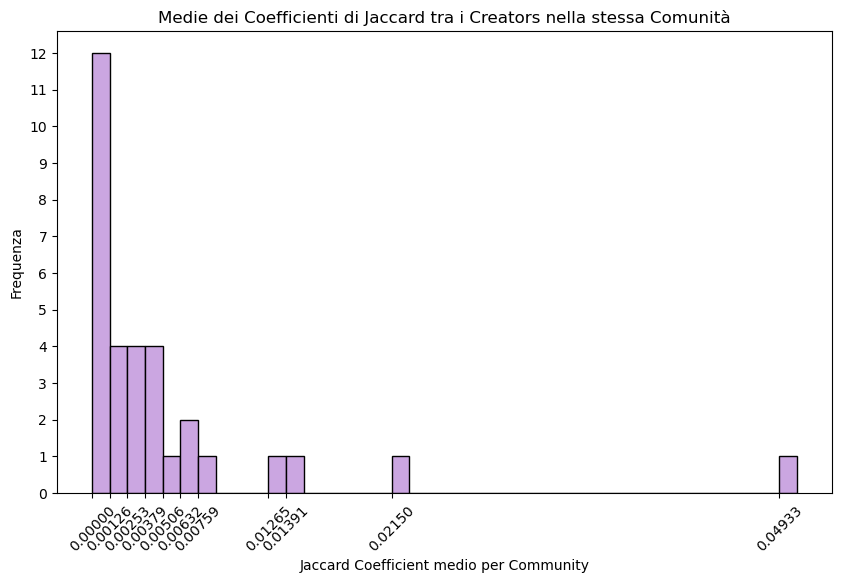

Media della distribuzione della media di audience overlapping: 0.005336184204508004


In [32]:
# Distribuzione
num_bins = 40  # Aumenta il numero di bins per avere una maggiore granularità

# Crea l'istogramma e ottieni i valori dei bins e le frequenze
hist, bin_edges = np.histogram(jaccard_mean_communtiesNodes, bins=num_bins)

# Crea un istogramma per visualizzare la distribuzione delle medie
plt.figure(figsize=(10, 6))
plt.hist(jaccard_mean_communtiesNodes, bins=num_bins, color='#cba6e1', edgecolor='black')

# Aggiungi titolo e etichette agli assi
plt.title("Medie dei Coefficienti di Jaccard tra i Creators nella stessa Comunità")
plt.xlabel("Jaccard Coefficient medio per Community")
plt.ylabel("Frequenza")

# Filtra i tick dell'asse x per mostrare solo quelli con occorrenze
x_ticks = bin_edges[:-1][hist > 0]  # Mostra solo i bordi dei bin con almeno un'occorrenza
plt.xticks(x_ticks, rotation=45)

# Aggiungi più tick sull'asse y per maggiore granularità
y_ticks = np.arange(0, max(hist) + 1, step=1)
plt.yticks(y_ticks)

# Mostra l'istogramma
plt.show()

# Calcolo della media della distribuzione
mean_value = np.mean(jaccard_mean_communtiesNodes)

print(f"Media della distribuzione della media di audience overlapping: {mean_value}")